## Importing the necessery libraries

In [2]:
#!pip install opencv-python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import os
from PIL import Image

c:\Users\Aarya Bhave\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


# Loading the folder path by segregating the sub-image folders as classes

In [3]:
data_path = "C:/codes/DL-CLG-PRAC/MDM 2 Dataset/new_test"
classes = [
    "BUDGET",
    "FORM",
    "INVOICE",
    "LETTER"
]
print("Loaded the dataset")

Loaded the dataset


# Extracting the image data using os from the folder

In [8]:
x_train = []
y_train = []
x_test = []
y_test = []

class_index = { "BUDGET" : 0, "FORM" : 1, "INVOICE" : 2, "LETTER" : 3}

for groups in classes:
    label = class_index[groups]
    for split in ["TRAIN", "TEST"]:
        switched_folder = os.path.join(data_path, groups, split)
        for file in os.listdir(switched_folder):
            if file.lower().endswith((".tif", ".tiff")):
                img = Image.open(os.path.join(switched_folder, file))
                img = img.convert("RGB")
                img = img.resize((64,64))
                if "TRAIN" in switched_folder:
                    x_train.append(np.array(img))
                    y_train.append(label)
                else:
                    x_test.append(np.array(img))
                    y_test.append(label)
                

x_train = np.array(x_train)
y_train = np.array(y_train)
x_test = np.array(x_test)
y_test = np.array(y_test)

In [10]:
print("For x:",x_train.shape)
print("For y:",y_train.shape)
print("For testing data x : ", x_test.shape)
print("For testing data y :", y_test.shape)

For x: (684, 64, 64, 3)
For y: (684,)
For testing data x :  (684, 64, 64, 3)
For testing data y : (684,)


# Splitting the data using train_test_split for training, validation, testing

In [11]:
#X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=3)
X_val, X_vtest, y_val, y_vtest = train_test_split(x_test, y_test, test_size=0.5, random_state=3)

print(x_train.shape, X_val.shape, X_vtest.shape)

(684, 64, 64, 3) (342, 64, 64, 3) (342, 64, 64, 3)


# Normalizing the image data

In [12]:
print("Normalising the image data")
X_train = x_train/255.0
X_val = X_val/255.0
X_vtest = X_vtest/255.0

Normalising the image data


# Building the CNN Network

In [13]:
input_shape = (64,64,3)
model = Sequential()

model.add(Conv2D(32, kernel_size=(3,3), activation='relu', input_shape = input_shape))
model.add(MaxPool2D((2,2)))

model.add(Conv2D(64, kernel_size=(3,3), activation='relu'))
model.add(MaxPool2D((2,2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(10, activation='softmax'))


c:\Users\Aarya Bhave\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Compiling the model

In [14]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Training the model

In [19]:
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), shuffle=True, batch_size=32)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.6301 - loss: 0.9125 - val_accuracy: 0.4415 - val_loss: 1.3585
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.6433 - loss: 0.8958 - val_accuracy: 0.5292 - val_loss: 1.2485
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.6857 - loss: 0.7834 - val_accuracy: 0.4854 - val_loss: 1.4487
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7208 - loss: 0.7672 - val_accuracy: 0.5409 - val_loss: 1.2371
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.7222 - loss: 0.7407 - val_accuracy: 0.5292 - val_loss: 1.3177
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.7617 - loss: 0.6486 - val_accuracy: 0.5731 - val_loss: 1.3201
Epoch 7/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.7763 - loss: 0.5798 - val_accuracy: 0.5351 - val_loss: 1.5532
Epoch 8/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.7690 - loss: 0.5525 - val_accuracy: 0.5497 - v

# Calculating the accuracy

In [20]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Accuracy : ", test_accuracy)

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6711 - loss: 390.5422
Accuracy :  0.6710526347160339


In [27]:
train_loss, train_accuracy = model.evaluate(X_train, y_train)
print("Training Accuracy : ", train_accuracy)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9956 - loss: 0.0225
Training Accuracy :  0.9956140518188477


In [24]:
from sklearn.metrics import confusion_matrix, classification_report

predictions = model.predict(x_test)
y_pred = np.argmax(
    predictions,
    axis=1
)
cm = confusion_matrix(
    y_test,
    y_pred
)
print(cm)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
[[105  29  26  11]
 [ 13 133  13  12]
 [ 20  45 102   4]
 [ 13  24  15 119]]


In [25]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=classes
    )
)

              precision    recall  f1-score   support

      BUDGET       0.70      0.61      0.65       171
        FORM       0.58      0.78      0.66       171
     INVOICE       0.65      0.60      0.62       171
      LETTER       0.82      0.70      0.75       171

    accuracy                           0.67       684
   macro avg       0.69      0.67      0.67       684
weighted avg       0.69      0.67      0.67       684



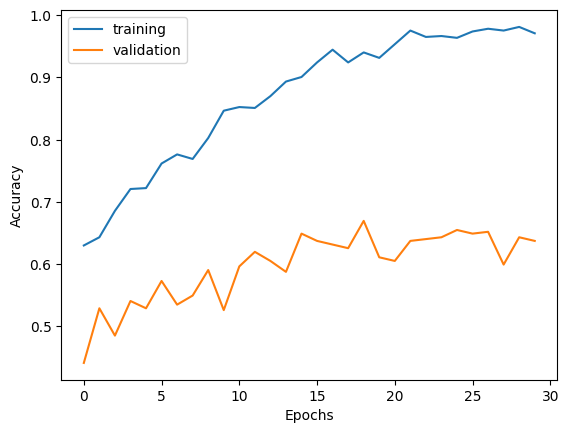

In [23]:
plt.plot(history.history["accuracy"], label='training')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

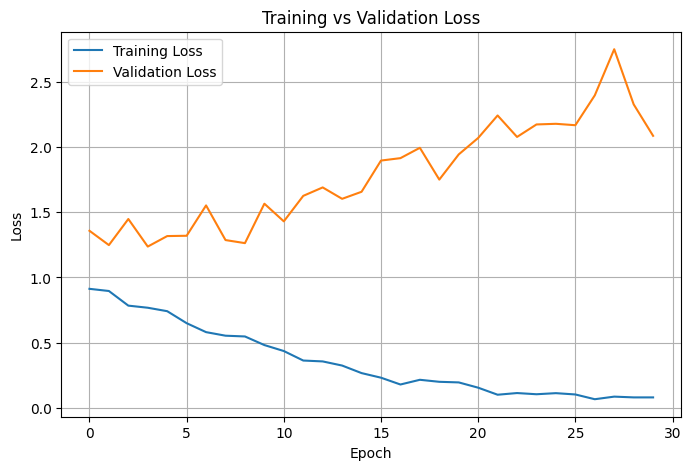

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Training vs Validation Loss"
)
plt.legend()
plt.grid()
plt.show()